## Target Distribution

In [21]:
print(df["isFraud"].value_counts())
print("\nPercentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


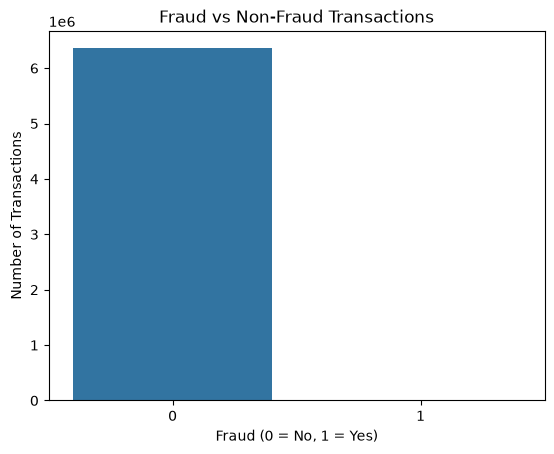

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="isFraud")
plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Number of Transactions")
plt.show()

## Fraud by Transaction Type

In [23]:
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"]
)

fraud_by_type

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [24]:
fraud_by_type["fraud_rate"] = (
    fraud_by_type[1] /
    fraud_by_type.sum(axis=1)
) * 100

fraud_by_type

isFraud,0,1,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2233384,4116,0.183955
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,528812,4097,0.768799


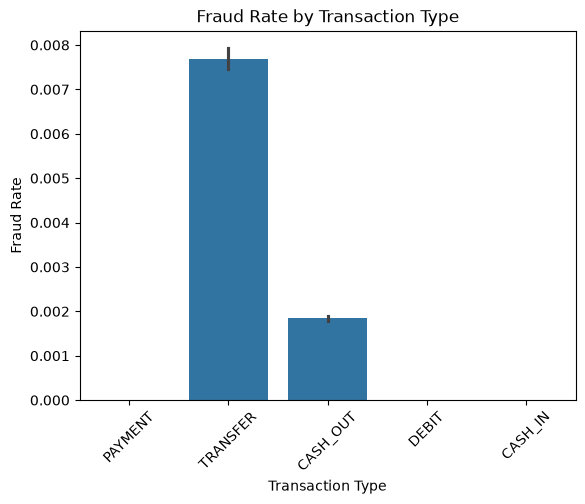

In [25]:
sns.barplot(
    data=df,
    x="type",
    y="isFraud",
    estimator="mean"
)

plt.title("Fraud Rate by Transaction Type")
plt.ylabel("Fraud Rate")
plt.xlabel("Transaction Type")
plt.xticks(rotation=45)
plt.show()

## Fraud vs Transaction Amount

In [26]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


In [27]:
sample_df = df.sample(
    n=100_000,
    random_state=42
)

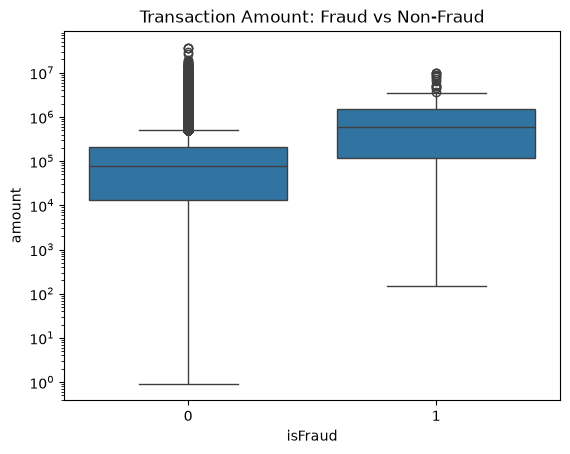

In [28]:
sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")
plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.show()

## Transaction Amount Analysis

In [29]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


In [30]:
df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
isFraud,,,,,
0,6354407,1.781970e+05,74684.72,0.01,92445516.64
1,8213,1.467967e+06,441423.44,0.00,10000000.00


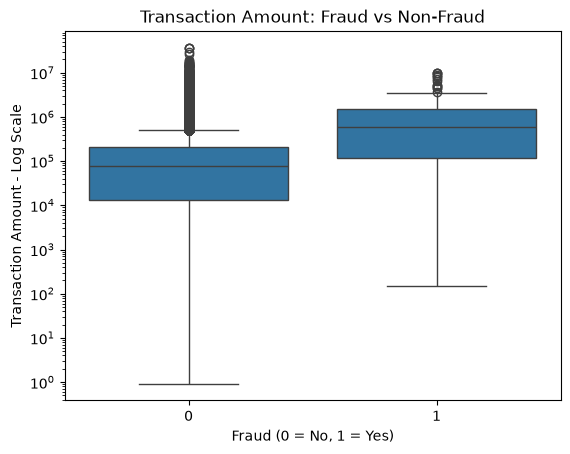

In [31]:
sample_df = df.sample(
    n=100_000,
    random_state=42
)

sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")
plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount - Log Scale")
plt.show()

In [32]:
fraud_df = df[df["isFraud"] == 1]

fraud_df["amount"].describe()


count    8.213000e+03
mean     1.467967e+06
std      2.404253e+06
min      0.000000e+00
25%      1.270913e+05
50%      4.414234e+05
75%      1.517771e+06
max      1.000000e+07
Name: amount, dtype: float64

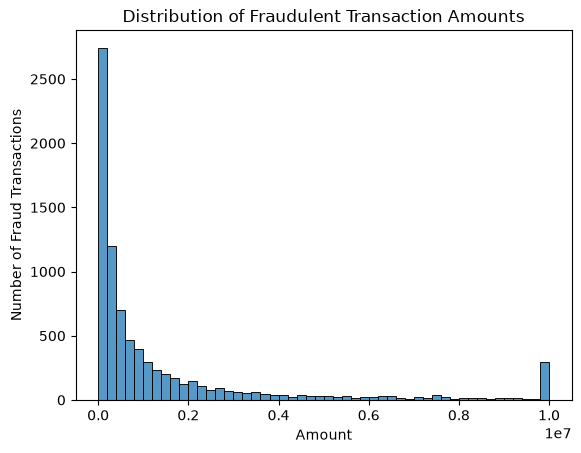

In [33]:
sns.histplot(
    data=fraud_df,
    x="amount",
    bins=50
)

plt.title("Distribution of Fraudulent Transaction Amounts")
plt.xlabel("Amount")
plt.ylabel("Number of Fraud Transactions")
plt.show()

In [34]:
df.groupby("type")["amount"].agg(
    ["count", "mean", "median", "max"]
)

,count,mean,median,max
type,,,,
CASH_IN,1399284,168920.242004,143427.710,1915267.90
CASH_OUT,2237500,176273.964346,147072.185,10000000.00
DEBIT,41432,5483.665314,3048.990,569077.51
PAYMENT,2151495,13057.604660,9482.190,238637.98
TRANSFER,532909,910647.009645,486308.390,92445516.64


## Balance Analysis

In [35]:
df.groupby("isFraud")[
    ["oldbalanceOrg", "newbalanceOrig",
     "oldbalanceDest", "newbalanceDest"]
].mean()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,8.328287e+05,855970.228109,1.101421e+06,1.224926e+06
1,1.649668e+06,192392.631836,5.442496e+05,1.279708e+06


In [36]:
df.groupby("isFraud")[
    ["oldbalanceOrg", "newbalanceOrig",
     "oldbalanceDest", "newbalanceDest"]
].median()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,14069.00,0.0,133311.8,214881.70
1,438983.45,0.0,0.0,4676.42


In [37]:
df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["destination_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

In [38]:
df.groupby("isFraud")[
    ["origin_balance_change",
     "destination_balance_change"]
].describe()

origin_balance_change                                         \
                        count          mean           std        min   
isFraud                                                                
0                   6354407.0 -2.314152e+04  1.062233e+05 -1915267.9   
1                      8213.0  1.457275e+06  2.396099e+06        0.0   

                                                         \
               25%        50%          75%          max   
isFraud                                                   
0             0.00       0.00    10102.125   4164236.31   
1        124582.58  436317.49  1503034.860  10000000.00   

        destination_balance_change                                            \
                             count           mean           std          min   
isFraud                                                                        
0                        6354407.0  123504.809994  8.104223e+05 -13060826.21   
1                           8213.0  735457.998071  1.856984e+06   -315226.07   

                                            
         25%  50%        75%           max  
isFraud                                     
0        0.0  0.0  148982.64  1.056878e+08  
1        0.0  0.0  445257.43  1.491511e+07

In [39]:
df["origin_balance_error"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
)

In [40]:
df["destination_balance_error"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
)

In [41]:
df.groupby("isFraud")[
    ["origin_balance_error",
     "destination_balance_error"]
].describe()

origin_balance_error                                             \
                       count           mean            std          min   
isFraud                                                                   
0                  6354407.0 -201338.558109  606928.890826 -92445516.64   
1                     8213.0  -10692.325265  265146.131130 -10000000.00   

                                                      \
               25%       50%       75%           max   
isFraud                                                
0       -249953.43 -69049.31 -3034.305  1.000000e-02   
1             0.00      0.00     0.000  3.725290e-09   

        destination_balance_error                                            \
                            count           mean           std          min   
isFraud                                                                       
0                       6354407.0   54692.231734  4.360026e+05 -75885725.63   
1                          8213.0  732509.301069  1.867748e+06  -8875516.29   

                                                
         25%      50%         75%          max  
isFraud                                         
0        0.0  3500.68   29259.805  13191233.98  
1        0.0  2231.46  442722.010  10000000.00

## Visualize Origin Balance Change

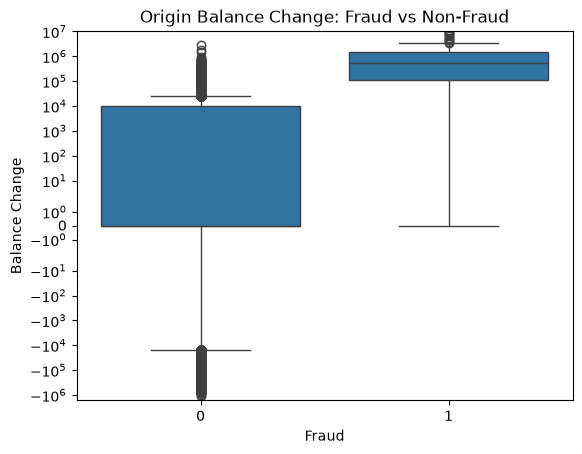

In [42]:
sample_df = df.sample(
    n=100_000,
    random_state=42
)

sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="origin_balance_change"
)

plt.yscale("symlog")
plt.title("Origin Balance Change: Fraud vs Non-Fraud")
plt.xlabel("Fraud")
plt.ylabel("Balance Change")
plt.show()

## isFlaggedFraud Analysis

In [43]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [44]:
df["isFlaggedFraud"].value_counts(normalize=True) * 100

isFlaggedFraud
0    99.999749
1     0.000251
Name: proportion, dtype: float64

In [45]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"]
)

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


In [46]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    normalize="index"
) * 100

isFraud,0,1
isFlaggedFraud,,
0,99.871169,0.128831
1,0.000000,100.000000


In [47]:
pd.crosstab(
    [df["type"], df["isFlaggedFraud"]],
    df["isFraud"]
)

isFraud                        0     1
type     isFlaggedFraud               
CASH_IN  0               1399284     0
CASH_OUT 0               2233384  4116
DEBIT    0                 41432     0
PAYMENT  0               2151495     0
TRANSFER 0                528812  4081
         1                     0    16

## Time Analysis

In [48]:
df["step"].describe()

count    6.362620e+06
mean     2.433972e+02
std      1.423320e+02
min      1.000000e+00
25%      1.560000e+02
50%      2.390000e+02
75%      3.350000e+02
max      7.430000e+02
Name: step, dtype: float64

In [49]:
df.groupby("step")["isFraud"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
step,,,
1,2708,16,0.005908
2,1014,8,0.007890
3,552,4,0.007246
4,565,10,0.017699
5,665,6,0.009023
...,...,...,...
739,10,10,1.000000
740,6,6,1.000000
741,22,22,1.000000


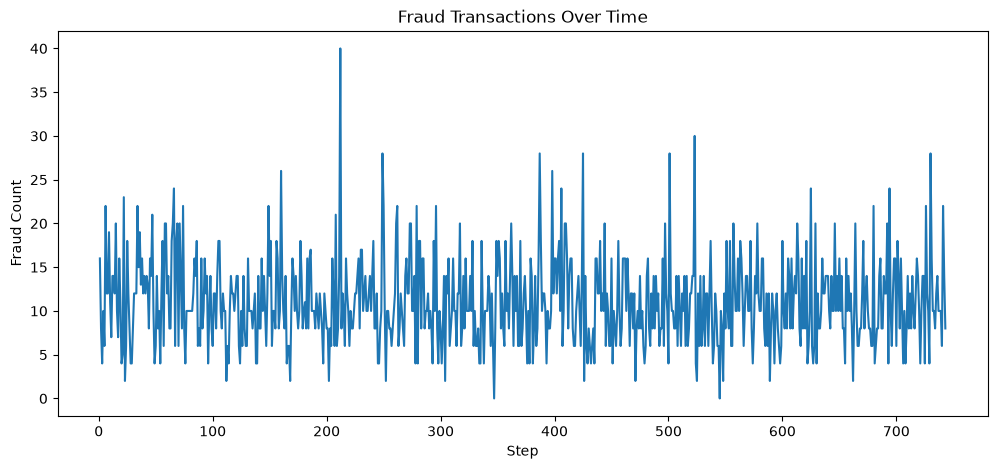

In [50]:
fraud_by_step = df.groupby("step")["isFraud"].sum()

fraud_by_step.plot(figsize=(12, 5))

plt.title("Fraud Transactions Over Time")
plt.xlabel("Step")
plt.ylabel("Fraud Count")
plt.show()

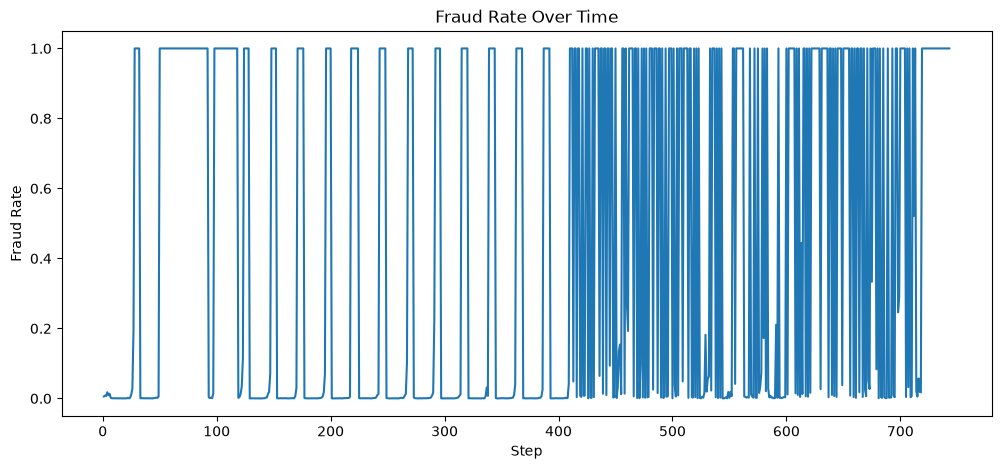

In [51]:
fraud_rate_by_step = df.groupby("step")["isFraud"].mean()

fraud_rate_by_step.plot(figsize=(12, 5))

plt.title("Fraud Rate Over Time")
plt.xlabel("Step")
plt.ylabel("Fraud Rate")
plt.show()

## Outlier Analysis

In [52]:
num_cols = df.select_dtypes(include="number").columns

print(num_cols)

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'hour',
       'orig_balance_diff', 'origin_balance_change',
       'destination_balance_change', 'origin_balance_error',
       'destination_balance_error'],
      dtype='object')


In [53]:
sample_df = df.sample(
    n=100_000,
    random_state=42
)

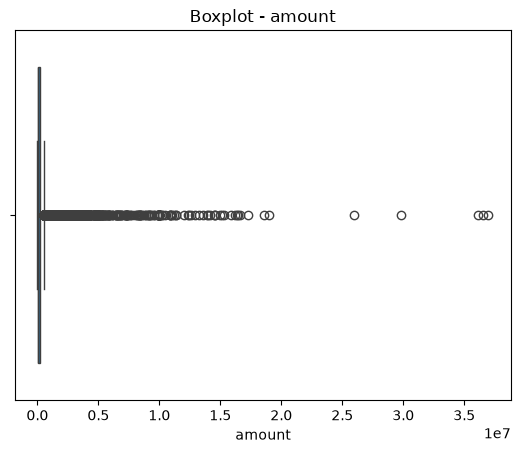

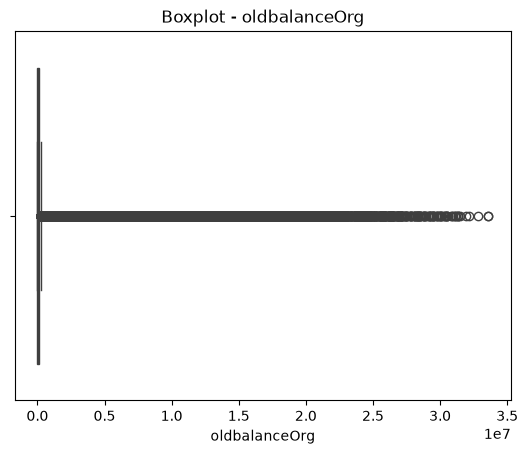

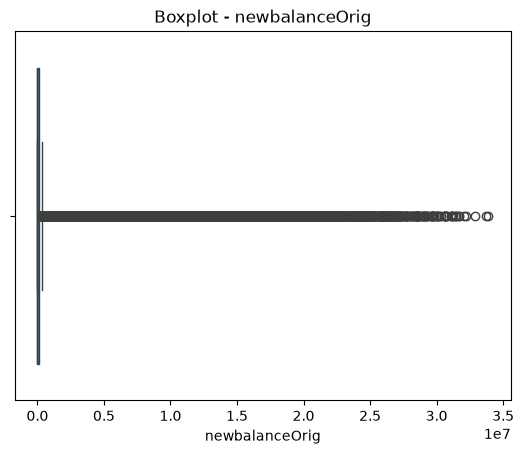

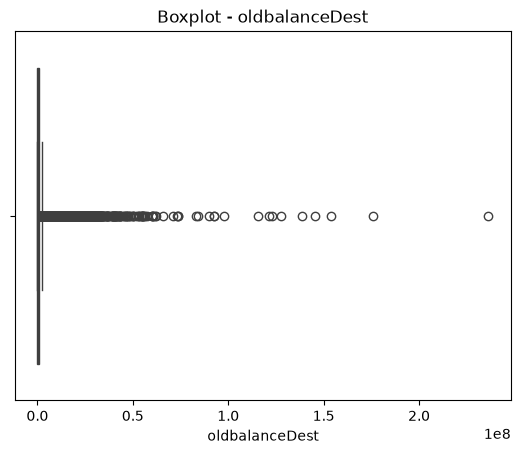

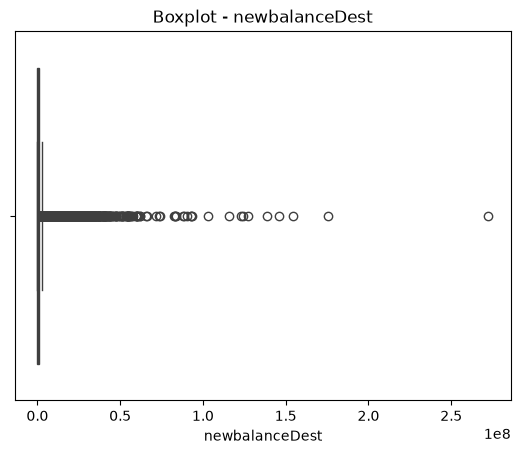

In [54]:
for col in [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]:
    sns.boxplot(x=sample_df[col])
    plt.title(f"Boxplot - {col}")
    plt.show()

In [55]:
Q1 = df["amount"].quantile(0.25)
Q3 = df["amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower:", lower)
print("Upper:", upper)

Lower: -279608.29125
Upper: 501719.33875


In [56]:
outliers = df[
    (df["amount"] < lower) |
    (df["amount"] > upper)
]

print("Potential outliers:", len(outliers))

Potential outliers: 338078


## Correlation Analysis

In [57]:
corr = df[
    [
        "step",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest",
        "isFraud",
        "isFlaggedFraud"
    ]
].corr()

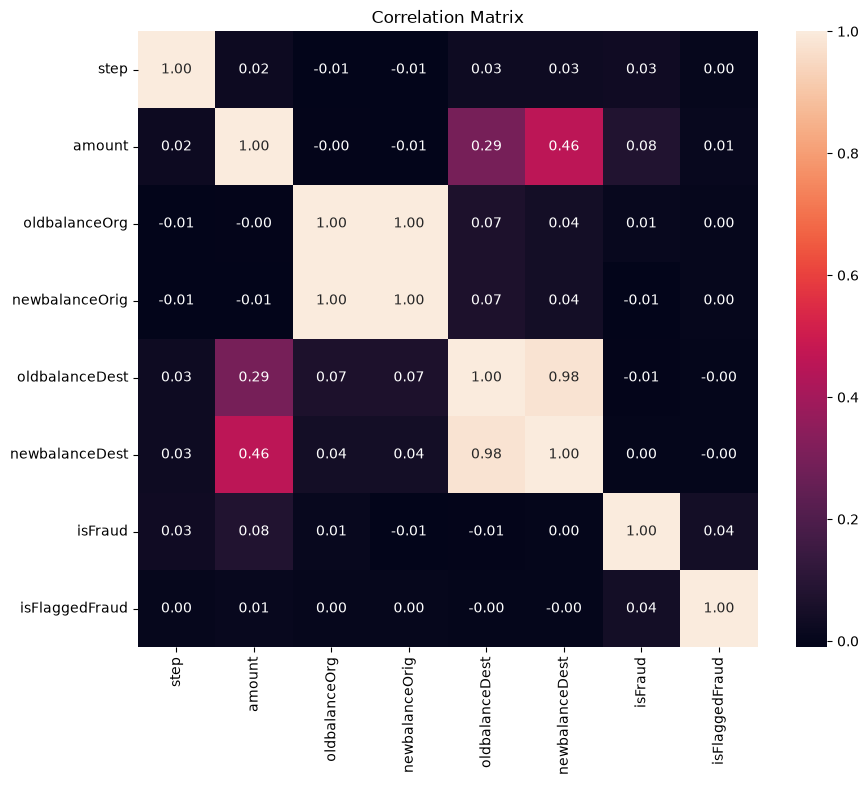

In [58]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()